# Phase 6 — Decision support: risk × value and budget simulation

**Question:** if the business can only afford to contact part of its customer base, whom should it choose to retain the most revenue? Does ranking by a model's predicted probabilities beat simple rules that do not use a model?

**Inputs:** `prediction_dataset.parquet`, `phase4_test_predictions.parquet` (probabilities of the 6 models on S6–S7), `transactions_clean.parquet`, the tuning folds (`tuning_folds.pkl`).
**Outputs:** `outputs/tables/phase6_*.csv`, `outputs/figures/phase6_*.png`.

**Definitions (fixed before looking at the results)** — details in `src/decision.py`:
- `v` = the customer's revenue in the quarter just ended, scaled to 30 days (known at t).
- `L` = actual revenue decline in the next quarter = max(0, v − next-quarter revenue). **Used for scoring only.**
- `V(s)` = mean revenue by state (on training data); a *downgrade* = a move to a state with a lower V.
- `r` = downgrade probability from XGBoost Config B; `EL = r × v` (expected loss).

**Transparency note.** The original plan was (1) to calibrate the probabilities with isotonic regression on a validation fold and (2) to score rules on the *total* revenue decline `L`. After seeing the results we added: a comparison with the uncalibrated probabilities (isotonic creates many ties and destroys the ranking), a split of `L` into the part due to customers *stopping* and the part due to *downgrades*, and two models that predict the outcome directly (probability of stopping, regression of next-quarter revenue). All results — including those of the original plan — are reported; the additions are labelled as analyses made after seeing the results.

In [1]:
import sys, warnings, pickle
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, joblib, matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, r2_score, mean_absolute_error, brier_score_loss
from xgboost import XGBClassifier, XGBRegressor
from config import PROCESSED, INTERIM, FIGURES, TABLES, ROOT, N_STATES, STATE_NAMES, STATE_COLORS, CURRENT_FEATURES, RANDOM_STATE
from modeling import to_xy, fit, CONFIGS
from decision import (period_revenue, attach_revenue, state_values, downgrade_mask, downgrade_risk, segment_risk,
                      captured_share, gain_curve, profit_curve, bootstrap_captured_diff)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0",
                     "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.edgecolor": "#9a9a92", "font.size": 10, "lines.linewidth": 2})
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
SHORT = {0: "Dormant", 1: "Lapsing", 2: "Recent", 3: "Active"}

## 1. Quarterly revenue and the value of each state

In [2]:
pur = pd.read_parquet(INTERIM / "transactions_clean.parquet")
rev = period_revenue(pur)
ds = attach_revenue(pd.read_parquet(PROCESSED / "prediction_dataset.parquet"), rev)
train_all = ds[ds["split"] == "train"]                   # all training origins S1–S5 (targets up to S6) — test results untouched
V = state_values(train_all, N_STATES)
D = downgrade_mask(V)
seg_risk = segment_risk(train_all, D, N_STATES)
state_table = pd.DataFrame({"state": [STATE_NAMES[s] for s in range(N_STATES)], "V_revenue_per_30d": V.values,
                            "downgrade_rate_train": seg_risk.values})
state_table

,state,V_revenue_per_30d,downgrade_rate_train
0,Dormant Low-Value,2.358,0.000
1,Lapsing Mid-Value,80.219,0.051
2,Recent Low-Frequency,129.943,0.791
3,Active High-Value,615.714,0.142


**Reading the table.** By revenue the states are ordered Dormant < Lapsing < Recent < Active: *Recent Low-Frequency* customers (who have just bought) spend more on average in that quarter than *Lapsing* customers. A Recent → Lapsing move therefore also counts as a downgrade in revenue terms, and the Recent group has a very high downgrade rate. Dormant customers cannot fall any further.

## 2. Downgrade risk from the model (XGBoost Config B) and calibration check

In [3]:
te = pd.read_parquet(PROCESSED / "phase4_test_predictions.parquet")
te = attach_revenue(te, rev)
seg = te["Segment_t"].astype(int).values
nxt = te["Segment_t+1"].astype(int).values
te["down"] = D[seg, nxt]
te["stop"] = (te["v"] > 0) & (te["rev_next"] == 0)
P = te[[f"proba_XGBoost_B_{k}" for k in range(N_STATES)]].values
te["r_raw"] = downgrade_risk(P, seg, D)

# Isotonic calibration on fold 2 (train S3–S4 -> validation S5; states re-fitted inside the fold as in Phase 4)
folds = pickle.load(open(INTERIM / "tuning_folds.pkl", "rb"))
trf, vaf = folds[2][0], folds[2][1]
pipe = clone(joblib.load(ROOT / "models" / "final_XGBoost_B.joblib")); pipe.balanced_ = True
fit("XGBoost", pipe, *to_xy(trf, CONFIGS["B"]))
Pv = pipe.predict_proba(to_xy(vaf, CONFIGS["B"])[0])
sv, yv = vaf["Segment_t"].astype(int).values, vaf["Segment_t+1"].astype(int).values
r_val, d_val = downgrade_risk(Pv, sv, D), D[sv, yv]
iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(r_val, d_val)
te["r_iso"] = iso.predict(te["r_raw"])
calib_summary = pd.DataFrame({
    "AUC (downgrade)": [roc_auc_score(te["down"], te["r_raw"])] * 2,
    "Brier": [brier_score_loss(te["down"], te["r_raw"]), brier_score_loss(te["down"], te["r_iso"])],
    "distinct values": [te["r_raw"].nunique(), te["r_iso"].nunique()]}, index=["raw", "isotonic"])
calib_summary

,AUC (downgrade),Brier,distinct values
raw,0.979,0.029,5517
isotonic,0.979,0.030,65


**Conclusion.** The raw XGBoost probabilities are already close to the observed rates (lower Brier score than the isotonic version), and isotonic regression groups many customers into the same value, which destroys the ranking. From here on the **raw probabilities** (`r_raw`) are used; results with isotonic calibration are still reported in the comparison table.

## 3. Where does the lost revenue come from?

Before comparing ways of selecting customers, we need to know which customers the revenue decline in S6–S7 actually comes from.

In [4]:
tot = te["L"].sum()
decomp = pd.Series({
    "Stayed in the same state": te.loc[nxt == seg, "L"].sum() / tot,
    "Downgraded (by V)": te.loc[te["down"], "L"].sum() / tot,
    "Upgraded": te.loc[(nxt != seg) & ~te["down"], "L"].sum() / tot,
    "— of which: stopped buying entirely next quarter": te.loc[te["stop"], "L"].sum() / tot}, name="share_of_total_L")
by_state = (te.groupby("Segment_t")["L"].sum() / tot).rename(index=STATE_NAMES)
print(f"Total revenue decline (30 days, both test origins): £{tot:,.0f}; share of rows downgrading {te['down'].mean():.1%}, share of rows with L>0 {(te['L']>0).mean():.1%}")
display(decomp.to_frame()); display(by_state.to_frame("share_of_total_L"))

Total revenue decline (30 days, both test origins): £330,465; share of rows downgrading 6.8%, share of rows with L>0 20.9%


,share_of_total_L
Stayed in the same state,0.792
Downgraded (by V),0.193
Upgraded,0.014
— of which: stopped buying entirely next quarter,0.504


,share_of_total_L
Segment_t,
Dormant Low-Value,0.008
Lapsing Mid-Value,0.207
Recent Low-Frequency,0.080
Active High-Value,0.705


**Main finding.** Only about 1/5 of the lost revenue comes from customers who *move to a lower state*; about 4/5 comes from customers who *stay in the same state* but buy less, and about half of the total lost revenue is due to customers who stop buying entirely in the next quarter. The reason: with cumulative RFM, a customer who has accumulated many orders is still classed as Active even without buying in the next quarter. We therefore evaluate against **three** definitions of loss:
- `L` — total revenue decline (the original definition; it also includes batch/seasonal fluctuation in wholesale buying, most of which cannot be "saved").
- `L_stop` — revenue lost because customers **stop buying** in the next quarter: this is what a retention campaign targets, and it is the main measure for the budget simulation.
- `L_down` — revenue lost through **downgrades**: exactly the event the state model predicts (this measure favours the state model and is shown for reference only).

In [5]:
te["L_stop"] = np.where(te["stop"], te["v"], 0.0)
te["L_down"] = np.where(te["down"], te["L"], 0.0)
outcome_totals = te[["L", "L_stop", "L_down"]].sum()
outcome_totals

L        330,465.019
L_stop   166,441.645
L_down    63,926.483
dtype: float64

## 4. Two direct prediction models (added after seeing the results)

Because cumulative states do not reflect customers who stop buying, we also predict the business outcome directly, using **the same features and the same training rows** as Phase 4 (origins S3–S5, history-eligible), plus `v`:
- **Stop-buying classifier:** P(customer stops buying in the next quarter | currently has revenue) → `EL_stop = P(stop) × v`.
- **Regression of next-quarter revenue (one-quarter CLV):** XGBoost with a Tweedie loss (suited to revenue with many zeros and a right skew) → `EL_reg = max(0, v − predicted revenue)`.

Hyperparameters are fixed at reasonable values (400 trees, depth 4, learning rate 0.05) without further tuning, to avoid fitting to the test set.

In [6]:
ds_h = ds[ds["history_eligible"]].copy()
ds_h["v_feat"] = ds_h["v"]
FEATS = CURRENT_FEATURES + ["v_feat", "Segment_t", "Segment_t-1", "Segment_t-2", "StateDuration"]
Xf = lambda d: d[FEATS].astype(float)
trh = ds_h[ds_h["split"] == "train"]
trp = trh[trh["v"] > 0]
clf = XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                    random_state=RANDOM_STATE, n_jobs=4, eval_metric="logloss").fit(Xf(trp), (trp["rev_next"] == 0).astype(int))
reg = XGBRegressor(objective="reg:tweedie", tweedie_variance_power=1.5, n_estimators=400, max_depth=4, learning_rate=0.05,
                   subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=4).fit(Xf(trh), trh["rev_next"])
te = te.merge(ds_h.loc[ds_h["split"] == "test", ["CustomerID", "origin"] + [c for c in FEATS if c != "Segment_t"]],
              on=["CustomerID", "origin"], how="left")
active = te["v"] > 0
te["p_stop"] = np.where(active, clf.predict_proba(Xf(te))[:, 1], 0.0)
te["rev_hat"] = reg.predict(Xf(te))
direct_eval = pd.DataFrame({
    "metric": ["AUC P(stop) (customers with revenue)", "Observed stop rate", "R² regression", "MAE regression (£/30 days)",
               "R² benchmark 'next quarter = this quarter'", "MAE benchmark 'next quarter = this quarter'"],
    "value": [roc_auc_score(te.loc[active, "stop"], te.loc[active, "p_stop"]), te.loc[active, "stop"].mean(),
              r2_score(te["rev_next"], te["rev_hat"]), mean_absolute_error(te["rev_next"], te["rev_hat"]),
              r2_score(te["rev_next"], te["v"]), mean_absolute_error(te["rev_next"], te["v"])]})
direct_eval

,metric,value
0,AUC P(stop) (customers with revenue),0.763
1,Observed stop rate,0.344
2,R² regression,0.577
3,MAE regression (£/30 days),114.036
4,R² benchmark 'next quarter = this quarter',0.697
5,MAE benchmark 'next quarter = this quarter',111.236


**Reading the results.** The stop-buying model discriminates fairly well (AUC ≈ 0.76). The next-quarter revenue regression, however, is **worse** than the simple benchmark "next quarter equals this quarter" in R²: quarterly revenue of wholesale customers is highly volatile, and the most recent spending level is already the best forecast of its size — similar to the Phase 4 conclusion that persistence is very hard to beat.

## 5. Comparing ways of selecting customers

In [7]:
te["EL_state"] = te["r_raw"] * te["v"]          # downgrade risk (state model) × value
te["EL_state_iso"] = te["r_iso"] * te["v"]
te["SEG_EL"] = seg_risk.reindex(seg).values * te["v"]   # mean risk of the current segment × value (no model)
te["EL_stop"] = te["p_stop"] * te["v"]
te["EL_reg"] = (te["v"] - te["rev_hat"]).clip(lower=0)
te["random"] = np.random.default_rng(RANDOM_STATE).random(len(te))
STRATS = {"random": "Random", "v": "Value only (largest spenders)", "SEG_EL": "Segment risk × value (no model)",
          "EL_state": "State-model risk × value", "EL_state_iso": "  — isotonic-calibrated version",
          "EL_stop": "Stop-model risk × value", "EL_reg": "Regression: expected decline"}
FRACS = [0.05, 0.10, 0.20]
rows = []
for out in ["L", "L_stop", "L_down"]:
    tmp = te.assign(L=te[out])
    for s, name in list(STRATS.items()) + [("L", "Oracle (perfect foresight)")]:
        rows.append({"outcome": out, "strategy": name, **{f"top {int(f*100)}%": captured_share(tmp, s, f) for f in FRACS}})
captured = pd.DataFrame(rows)
captured.pivot_table(index="strategy", columns="outcome", values="top 10%", sort=False)

outcome,L,L_stop,L_down
strategy,,,
Random,0.080,0.096,0.106
Value only (largest spenders),0.648,0.438,0.370
Segment risk × value (no model),0.600,0.395,0.556
State-model risk × value,0.390,0.430,0.948
— isotonic-calibrated version,0.292,0.432,0.943
Stop-model risk × value,0.574,0.605,0.644
Regression: expected decline,0.659,0.545,0.546
Oracle (perfect foresight),0.850,0.968,1.000


In [8]:
# 95 % confidence intervals (customer-level bootstrap, 1,000 draws) for the difference from "value only" at the 10 % contact level
ci_rows = []
for out, s in [("L_stop", "EL_stop"), ("L_stop", "EL_state"), ("L_stop", "SEG_EL"), ("L", "EL_stop"), ("L", "EL_state"), ("L", "EL_reg")]:
    tmp = te.assign(L=te[out])
    point = captured_share(tmp, s, 0.10) - captured_share(tmp, "v", 0.10)
    draws = bootstrap_captured_diff(tmp, s, "v", 0.10, n_boot=1000, seed=RANDOM_STATE)
    lo, hi = np.percentile(draws, [2.5, 97.5])
    ci_rows.append({"outcome": out, "strategy": STRATS[s], "diff_vs_value_top10": point, "ci_low": lo, "ci_high": hi})
ci_table = pd.DataFrame(ci_rows)
ci_table

,outcome,strategy,diff_vs_value_top10,ci_low,ci_high
0,L_stop,Stop-model risk × value,0.167,0.126,0.213
1,L_stop,State-model risk × value,-0.008,-0.068,0.051
2,L_stop,Segment risk × value (no model),-0.043,-0.074,-0.006
3,L,Stop-model risk × value,-0.073,-0.113,-0.042
4,L,State-model risk × value,-0.258,-0.359,-0.203
5,L,Regression: expected decline,0.011,-0.014,0.032


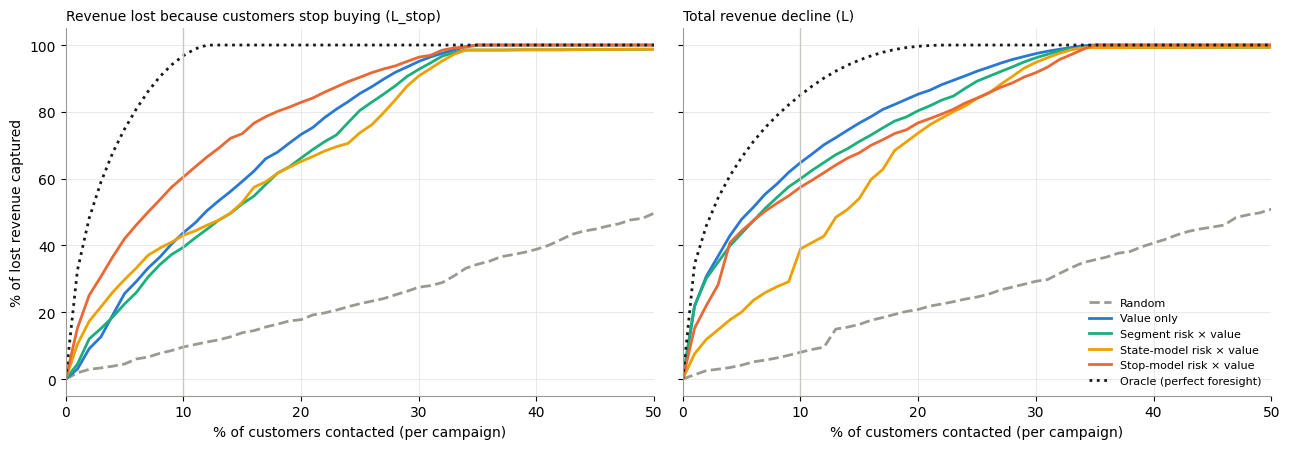

In [9]:
grid = np.linspace(0, 1, 101)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
show = [("random", "#9a9a92", "--"), ("v", "#2a78d6", "-"), ("SEG_EL", "#1baf7a", "-"), ("EL_state", "#eda100", "-"),
        ("EL_stop", "#eb6834", "-"), ("L", "#1a1a19", ":")]
labels = {**STRATS, "L": "Oracle (perfect foresight)"}
labels_en = {"random": "Random", "v": "Value only", "SEG_EL": "Segment risk × value", "EL_state": "State-model risk × value",
             "EL_stop": "Stop-model risk × value", "L": "Oracle (perfect foresight)"}
for ax, (out, title) in zip(axes, [("L_stop", "Revenue lost because customers stop buying (L_stop)"),
                                   ("L", "Total revenue decline (L)")]):
    tmp = te.assign(L=te[out])
    for s, col, ls in show:
        ax.plot(grid * 100, gain_curve(tmp, s if s != "L" else "L", grid) * 100, color=col, ls=ls, label=labels_en[s])
    ax.axvline(10, color="#c9c8c2", lw=1)
    ax.set_title(title, loc="left", fontsize=10); ax.set_xlabel("% of customers contacted (per campaign)")
    ax.set_xlim(0, 50)
axes[0].set_ylabel("% of lost revenue captured")
axes[1].legend(loc="lower right", fontsize=8, frameon=False)
fig.tight_layout(); fig.savefig(FIGURES / "phase6_gain_curves.png", dpi=150, bbox_inches="tight")

## 6. Budget simulation

Profit(N) = m · u · ΣL_stop(top N) − c · N, summed over two campaigns (origins S6 and S7). The parameters are **assumptions** (there are no real campaign data):
- `u` — share of the at-risk revenue that the campaign retains: 5 %, 10 %, 20 %
- `c` — cost per contacted customer (once per campaign): £2, £10, £25
- `m` — gross margin on revenue: 25 %

A campaign targets revenue over the **next quarter**, so the loss used in the simulation is the quarterly revenue that a customer who stops buying would have brought = 3 × `L_stop` (because `L_stop` is measured per 30 days). The ranking of customers does not change; only the profit level depends on this conversion.

In [10]:
M = 0.25
SIM_STRATS = ["v", "SEG_EL", "EL_state", "EL_stop"]
sim_df = te.assign(L=te["L_stop"] * 3)          # one quarter of revenue (3 × 30 days)
scen = []
curves = {}
for u in [0.05, 0.10, 0.20]:
    for c in [2, 10, 25]:
        for s in SIM_STRATS + ["random"]:
            pc = profit_curve(sim_df, s, u=u, c=c, m=M)
            curves[(u, c, s)] = pc
            best = pc.loc[pc["profit"].idxmax()]
            top10 = pc.iloc[(pc["frac"] - 0.10).abs().idxmin()]
            scen.append({"u": u, "c": c, "strategy": labels_en[s], "best_frac": best["frac"], "best_contacted": best["contacted"],
                         "best_profit": best["profit"], "profit_at_top10": top10["profit"]})
scenarios = pd.DataFrame(scen)
scenarios.pivot_table(index=["u", "c"], columns="strategy", values="best_profit", sort=False).round(0)

strategy  Value only  Segment risk × value  State-model risk × value  \
u     c                                                                
0.050 2    1,062.000               719.000                 1,054.000   
      10       0.000                 0.000                     0.000   
      25       0.000                 0.000                     0.000   
0.100 2    6,480.000             6,319.000                 6,213.000   
      10       0.000                 0.000                   397.000   
      25       0.000                 0.000                     0.000   
0.200 2   18,746.000            18,508.000                18,480.000   
      10   2,094.000             1,366.000                 3,139.000   
      25       0.000                 0.000                   524.000   

strategy  Stop-model risk × value    Random  
u     c                                      
0.050 2                 1,992.000     0.000  
      10                  148.000     0.000  
      25                    0.000     0.000  
0.100 2                 6,802.000    50.000  
      10                1,331.000     0.000  
      25                   71.000     0.000  
0.200 2                18,837.000 7,181.000  
      10                6,322.000     0.000  
      25                1,875.000     0.000

In [11]:
# Break-even: minimum retention rate u at which contacting the top 10 % does not make a loss
be = []
for s in SIM_STRATS:
    got = captured_share(sim_df, s, 0.10) * sim_df["L"].sum()
    n10 = sum(int(round(0.10 * len(g))) for _, g in sim_df.groupby("origin"))
    for c in [2, 10, 25]:
        be.append({"strategy": labels_en[s], "c": c, "contacted_top10": n10, "L_stop_captured": got, "break_even_u": c * n10 / (M * got)})
breakeven = pd.DataFrame(be)
breakeven.pivot_table(index="strategy", columns="c", values="break_even_u", sort=False)

c,2,10,25
strategy,,,
Value only,0.033,0.164,0.411
Segment risk × value,0.036,0.182,0.456
State-model risk × value,0.033,0.167,0.418
Stop-model risk × value,0.024,0.119,0.297


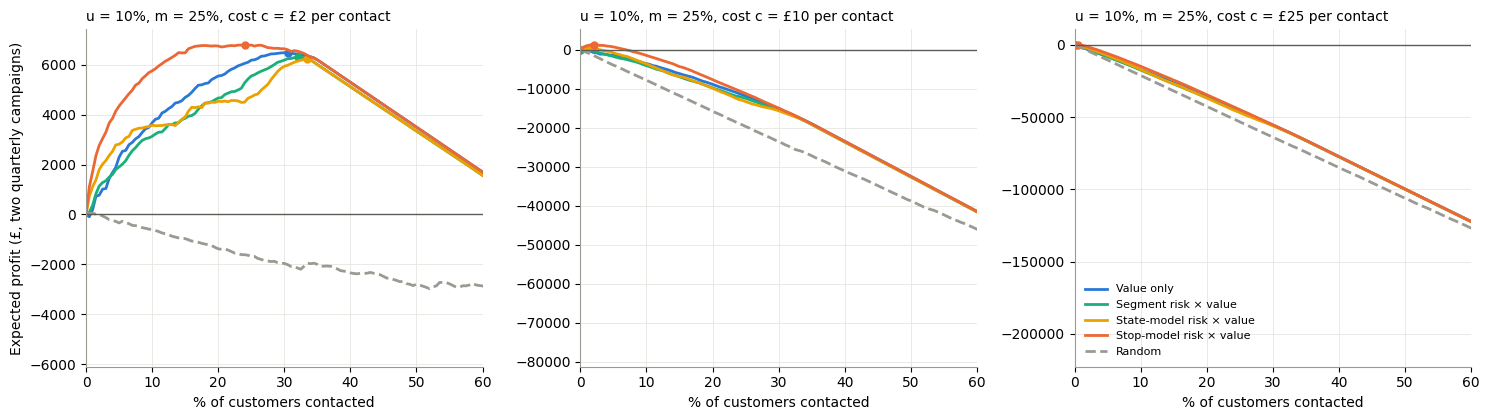

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=False)
cols = {"v": "#2a78d6", "SEG_EL": "#1baf7a", "EL_state": "#eda100", "EL_stop": "#eb6834", "random": "#9a9a92"}
for ax, c in zip(axes, [2, 10, 25]):
    for s in SIM_STRATS + ["random"]:
        pc = curves[(0.10, c, s)]
        ax.plot(pc["frac"] * 100, pc["profit"], color=cols[s], ls="--" if s == "random" else "-", label=labels_en[s])
        b = pc.loc[pc["profit"].idxmax()]
        if s != "random":
            ax.plot(b["frac"] * 100, b["profit"], "o", color=cols[s], ms=5)
    ax.axhline(0, color="#5c5c57", lw=1)
    ax.set_title(f"u = 10%, m = 25%, cost c = £{c} per contact", loc="left", fontsize=10)
    ax.set_xlabel("% of customers contacted"); ax.set_xlim(0, 60)
axes[0].set_ylabel("Expected profit (£, two quarterly campaigns)")
axes[2].legend(fontsize=8, frameon=False, loc="lower left")
fig.tight_layout(); fig.savefig(FIGURES / "phase6_profit_curves.png", dpi=150, bbox_inches="tight")

## 7. Example list: 20 customers to prioritise in the latest campaign (origin S7)

In [13]:
ACTION = {0: "Reactivation: win-back offer", 1: "Reminder to reorder familiar products", 2: "Incentive for the next order",
          3: "Personal follow-up (account manager)"}
top20 = (te[te["origin"] == "S7"].sort_values("EL_stop", ascending=False).head(20)
         .assign(state=lambda d: d["Segment_t"].map(STATE_NAMES), action=lambda d: d["Segment_t"].map(ACTION))
         [["CustomerID", "state", "v", "p_stop", "EL_stop", "action", "rev_next"]]
         .rename(columns={"rev_next": "rev_next (actual, for reference only)"}))
top20

,CustomerID,state,v,p_stop,EL_stop,action,"rev_next (actual, for reference only)"
4725,12931,Active High-Value,"9,180.026",0.314,"2,883.083",Personal follow-up (account manager),"3,683.426"
4358,12415,Active High-Value,"9,006.039",0.185,"1,665.445",Personal follow-up (account manager),"9,782.850"
4456,12557,Active High-Value,"1,352.067",0.926,"1,251.558",Personal follow-up (account manager),"1,281.429"
4330,12378,Lapsing Mid-Value,"1,307.159",0.940,"1,229.073",Reminder to reorder familiar products,0.000
4579,12744,Active High-Value,"1,287.822",0.942,"1,213.626",Personal follow-up (account manager),428.254
7936,16984,Active High-Value,"1,442.305",0.839,"1,209.521",Personal follow-up (account manager),0.000
4352,12409,Active High-Value,"1,584.991",0.750,"1,188.558",Personal follow-up (account manager),0.000
4375,12435,Active High-Value,"1,255.728",0.894,"1,122.478",Personal follow-up (account manager),0.000
5638,14088,Active High-Value,"3,299.964",0.333,"1,097.990",Personal follow-up (account manager),"10,707.394"
4402,12477,Active High-Value,"1,388.172",0.778,"1,079.962",Personal follow-up (account manager),"1,879.590"


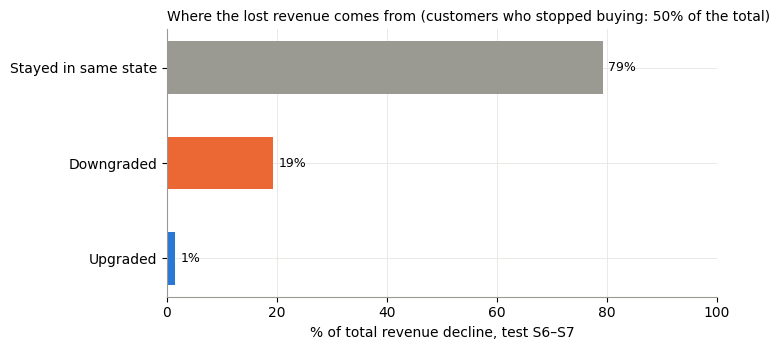

In [14]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
parts = pd.Series({"Stayed in same state": te.loc[nxt == seg, "L"].sum(), "Downgraded": te.loc[te["down"], "L"].sum(),
                   "Upgraded": te.loc[(nxt != seg) & ~te["down"], "L"].sum()}) / tot * 100
ax.barh(parts.index[::-1], parts.values[::-1], color=["#9a9a92", "#eb6834", "#2a78d6"][::-1], height=0.55)
stop_share = te.loc[te["stop"], "L"].sum() / tot * 100
for i, val in enumerate(parts.values[::-1]):
    ax.text(val + 1, i, f"{val:.0f}%", va="center", fontsize=9)
ax.set_xlim(0, 100); ax.set_xlabel("% of total revenue decline, test S6–S7")
ax.set_title(f"Where the lost revenue comes from (customers who stopped buying: {stop_share:.0f}% of the total)", loc="left", fontsize=10)
fig.tight_layout(); fig.savefig(FIGURES / "phase6_loss_decomposition.png", dpi=150, bbox_inches="tight")

In [15]:
state_table.to_csv(TABLES / "phase6_state_values.csv", index=False)
calib_summary.to_csv(TABLES / "phase6_calibration.csv")
pd.concat([decomp, by_state]).to_frame("share_of_total_L").to_csv(TABLES / "phase6_loss_decomposition.csv")
direct_eval.to_csv(TABLES / "phase6_direct_models.csv", index=False)
captured.to_csv(TABLES / "phase6_captured_share.csv", index=False)
ci_table.to_csv(TABLES / "phase6_bootstrap_ci.csv", index=False)
scenarios.to_csv(TABLES / "phase6_budget_scenarios.csv", index=False)
breakeven.to_csv(TABLES / "phase6_breakeven.csv", index=False)
top20.to_csv(TABLES / "phase6_top20_S7.csv", index=False)
print("saved")

saved
